# RNN — Parte 1: Preparación de Datos
### Dataset Jena Climate (2009–2016)

---

## ¿Qué hace este notebook?

Este notebook prepara el dataset climático de Jena para entrenar una Red Neuronal Recurrente (RNN) que **predice la temperatura 24 horas en el futuro**.

El flujo completo es:

```
CSV crudo  →  Exploración  →  Splits  →  Normalización  →  Guardar .npy
```

---

## Conceptos clave

| Concepto | Descripción |
|---|---|
| **Series temporales** | Datos ordenados en el tiempo donde el orden importa |
| **Train / Val / Test split** | Cómo dividir datos temporales sin "ver el futuro" |
| **Normalización (StandardScaler)** | Por qué escalar los datos acelera el entrenamiento |
| **Ventana deslizante** | Cómo construir pares (X, y) para una RNN |
| **Sampling rate** | Submuestrear para reducir costo computacional |


---
## Concepto: ¿Qué es una serie temporal?

Una **serie temporal** es una secuencia de valores medidos en intervalos regulares de tiempo.

```
Tiempo:       t=0    t=1    t=2    t=3    t=4   ...   t=N
Temperatura:  5.2°   5.8°   6.1°   5.9°   6.4°  ...   ?
```

La idea clave: **el valor en t=N depende de los valores anteriores**.
Por eso usamos RNNs — pueden "recordar" el pasado mientras procesan nueva información.

### ¿Por qué no usamos una red neuronal normal (MLP)?
- Un MLP trata cada muestra como **independiente**
- Una RNN mantiene un **estado oculto** que se actualiza en cada paso de tiempo
- Esto le permite capturar **dependencias temporales** (ej: la temperatura de hoy depende de la de ayer)


---
## Celda 1 — Importaciones y semilla de reproducibilidad


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler

# Semilla para reproducibilidad — siempre fijarla en clase
SEED = 42
np.random.seed(SEED)

# Estilo de gráficas
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11

print(' Librerías cargadas correctamente')

 Librerías cargadas correctamente


---
## Celda 2 — Descargar el dataset

El dataset Jena Climate contiene mediciones meteorológicas cada **10 minutos** entre 2009 y 2016, registradas en el Instituto Max Planck de Bioquímica, Jena (Alemania).

**Fuente:** [Kaggle — Jena Climate](https://www.kaggle.com/datasets/mnassrib/jena-climate)


In [ ]:
# Descarga directa desde el bucket S3 de Keras
!mkdir -p data
!wget -q -P data https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip -q data/jena_climate_2009_2016.csv.zip -d data
!rm  data/jena_climate_2009_2016.csv.zip

fname = 'data/jena_climate_2009_2016.csv'
print(f' Dataset descargado: {fname}')

replace data/jena_climate_2009_2016.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename:  Dataset descargado: data/jena_climate_2009_2016.csv


---
## Celda 3 — Exploración inicial del dataset (EDA)

Antes de cualquier modelado, siempre inspeccionamos los datos:
- ¿Cuántas filas y columnas?
- ¿Qué variables tenemos?
- ¿Hay valores faltantes?
- ¿Cuáles son las distribuciones básicas?


In [ ]:
df = pd.read_csv(fname)
df = df.drop(columns=['Date Time'])

print('=' * 50)
print(' FORMA DEL DATASET')
print('=' * 50)
print(f'  Filas    : {df.shape[0]:,}')
print(f'  Columnas : {df.shape[1]}')
print(f'  Período  : 2009-01-01 → 2016-12-31')
print(f'  Frecuencia: cada 10 minutos')
print()

print('=' * 50)
print('VARIABLES DISPONIBLES')
print('=' * 50)
for i, col in enumerate(df.columns):
    print(f'  [{i:02d}] {col}')
print()

print('=' * 50)
print(' VALORES FALTANTES')
print('=' * 50)
missing = df.isnull().sum()
if missing.sum() == 0:
    print(' Ninguno — dataset completo')
else:
    print(missing[missing > 0])
print()

print('=' * 50)
print('ESTADÍSTICAS DESCRIPTIVAS')
print('=' * 50)
df.describe().round(2)

 FORMA DEL DATASET
  Filas    : 420,451
  Columnas : 14
  Período  : 2009-01-01 → 2016-12-31
  Frecuencia: cada 10 minutos

VARIABLES DISPONIBLES
  [00] p (mbar)
  [01] T (degC)
  [02] Tpot (K)
  [03] Tdew (degC)
  [04] rh (%)
  [05] VPmax (mbar)
  [06] VPact (mbar)
  [07] VPdef (mbar)
  [08] sh (g/kg)
  [09] H2OC (mmol/mol)
  [10] rho (g/m**3)
  [11] wv (m/s)
  [12] max. wv (m/s)
  [13] wd (deg)

 VALORES FALTANTES
 Ninguno — dataset completo

ESTADÍSTICAS DESCRIPTIVAS


,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00,420451.00
mean,989.21,9.45,283.49,4.95,76.01,13.58,9.53,4.04,6.02,9.64,1216.07,2.13,3.53,174.73
std,8.36,8.42,8.50,6.73,16.48,7.74,4.18,4.90,2.66,4.24,39.98,1.54,2.34,86.68
min,913.60,-23.01,250.60,-25.01,12.95,0.95,0.79,0.00,0.50,0.80,1059.45,0.00,0.00,0.00
25%,984.20,3.36,277.43,0.24,65.21,7.78,6.21,0.87,3.92,6.29,1187.49,0.99,1.76,124.80
50%,989.57,9.41,283.46,5.21,79.30,11.82,8.86,2.19,5.59,8.96,1213.80,1.76,2.96,198.10
75%,994.72,15.47,289.53,10.07,89.40,17.60,12.35,5.30,7.80,12.48,1242.77,2.86,4.74,234.10
max,1015.35,37.28,311.34,23.11,100.00,63.77,28.32,46.01,18.13,28.82,1393.54,14.63,23.50,360.00


---
## Celda 4 — Visualización: Temperatura y Humedad (primeros 10 días)

Visualizamos los primeros 10 días para entender la **estructura temporal** de los datos.

> ** Patrón esperado:** La temperatura sube de día y baja de noche.
> La humedad hace lo contrario — patrón inverso clásico.


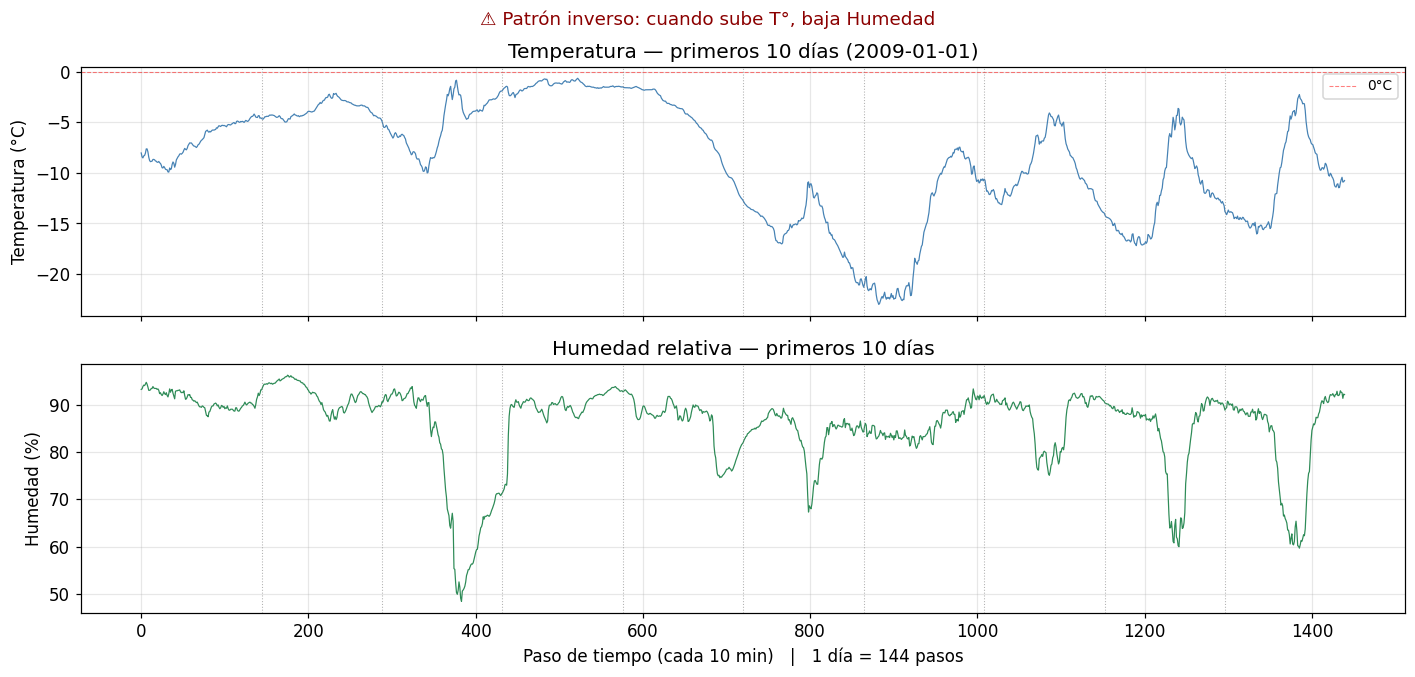

temperatura.shape = (420451,)
raw_data.shape    = (420451, 14)  ← (pasos_totales, num_features)


In [ ]:
# Extraemos como arrays numpy para facilitar el indexado
temperature = df['T (degC)'].values   # shape: (N,)  — solo temperatura
raw_data    = df.values               # shape: (N, 14) — todas las features

# 1 día = 144 pasos (6 mediciones/hora × 24 horas)
# 10 días = 1440 pasos
STEPS_PER_DAY = 6 * 24  # = 144
n_days_to_show = 10
n_steps = n_days_to_show * STEPS_PER_DAY

humidity = raw_data[:, 4]  # Índice 4 = 'rh (%)' — humedad relativa

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

# --- Temperatura ---
axes[0].plot(range(n_steps), temperature[:n_steps], color='steelblue', linewidth=0.8)
axes[0].set_title(f'Temperatura — primeros {n_days_to_show} días (2009-01-01)')
axes[0].set_ylabel('Temperatura (°C)')
axes[0].axhline(0, color='red', linestyle='--', linewidth=0.7, alpha=0.5, label='0°C')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# --- Humedad ---
axes[1].plot(range(n_steps), humidity[:n_steps], color='seagreen', linewidth=0.8)
axes[1].set_title(f'Humedad relativa — primeros {n_days_to_show} días')
axes[1].set_ylabel('Humedad (%)')
axes[1].set_xlabel(f'Paso de tiempo (cada 10 min)   |   1 día = {STEPS_PER_DAY} pasos')
axes[1].grid(alpha=0.3)

# Marcas de días
for day in range(1, n_days_to_show):
    for ax in axes:
        ax.axvline(day * STEPS_PER_DAY, color='gray', linestyle=':', linewidth=0.7, alpha=0.6)

plt.tight_layout()
plt.suptitle('Patrón inverso: cuando sube T°, baja Humedad', y=1.02, fontsize=12, color='darkred')
plt.show()

print(f'temperatura.shape = {temperature.shape}')
print(f'raw_data.shape    = {raw_data.shape}  ← (pasos_totales, num_features)')

---
## Concepto: División de datos en series temporales

En series temporales **NO** se puede mezclar los datos aleatoriamente (como se hace con imágenes).
Si se hace, estaríamos "viendo el futuro" durante el entrenamiento — un error grave llamado **data leakage**.

```
Datos originales ordenados cronológicamente:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
2009 ──────────────── 2012 ──────────── 2014 ──────── 2016
│                          │                  │              │
│◄──────── TRAIN (50%) ───►│◄── VAL (25%) ───►│◄── TEST ────►│
│                          │                  │              │
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

REGLA: el pasado entrena, el futuro evalúa. Nunca al revés.
```

| Split | Porcentaje | Propósito |
|---|---|---|
| **Train** | 50% | El modelo aprende de aquí |
| **Val** | 25% | Ajustamos hiperparámetros, detectamos overfitting |
| **Test** | 25% | Evaluación final — solo se toca una vez |


---
## Celda 5 — Crear los splits Train / Val / Test


In [ ]:
N = len(raw_data)

num_train_samples = int(0.50 * N)
num_val_samples   = int(0.25 * N)
num_test_samples  = N - num_train_samples - num_val_samples

print('=' * 55)
print('DIVISIÓN DEL DATASET')
print('=' * 55)
print(f'  Total de muestras : {N:>10,}')
print(f'  Train             : {num_train_samples:>10,}  ({num_train_samples/N*100:.1f}%)')
print(f'  Validación        : {num_val_samples:>10,}  ({num_val_samples/N*100:.1f}%)')
print(f'  Test              : {num_test_samples:>10,}  ({num_test_samples/N*100:.1f}%)')
print()
print(f'  ≈ Días de train : {num_train_samples // (6*24):,} días')
print(f'  ≈ Días de val   : {num_val_samples // (6*24):,} días')
print(f'  ≈ Días de test  : {num_test_samples // (6*24):,} días')

# Guardamos los índices (útiles para la Parte 4)
train_idx = np.arange(0, num_train_samples)
val_idx   = np.arange(num_train_samples, num_train_samples + num_val_samples)
test_idx  = np.arange(num_train_samples + num_val_samples, N)

DIVISIÓN DEL DATASET
  Total de muestras :    420,451
  Train             :    210,225  (50.0%)
  Validación        :    105,112  (25.0%)
  Test              :    105,114  (25.0%)

  ≈ Días de train : 1,459 días
  ≈ Días de val   : 729 días
  ≈ Días de test  : 729 días


---
## Celda 6 — Visualizar los splits sobre la serie temporal completa


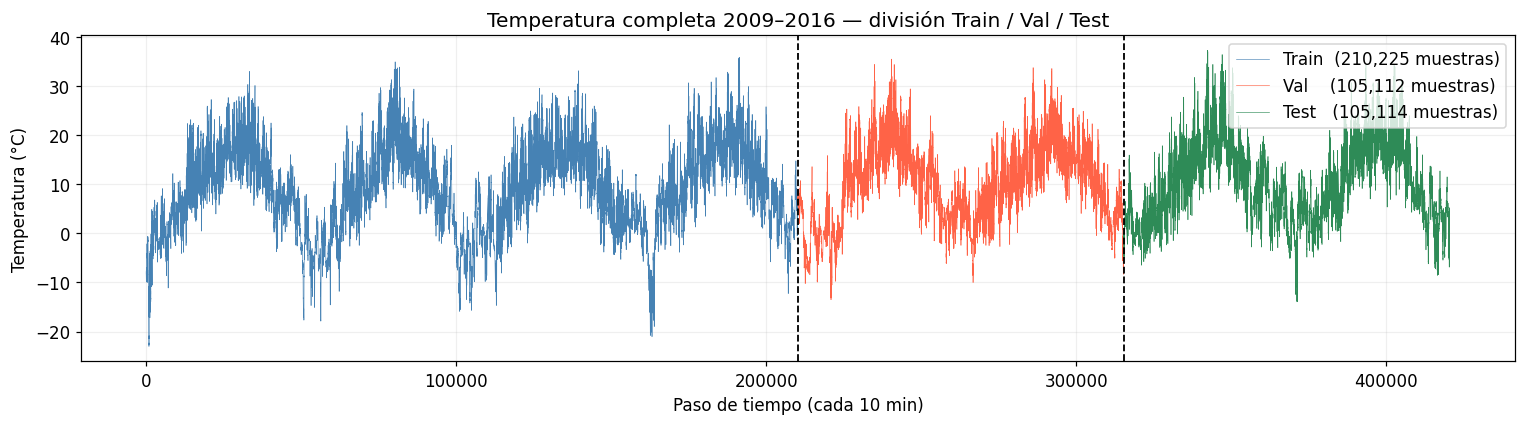

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))

train_temp = temperature[:num_train_samples]
val_temp   = temperature[num_train_samples : num_train_samples + num_val_samples]
test_temp  = temperature[num_train_samples + num_val_samples :]

ax.plot(range(len(train_temp)),
        train_temp, color='steelblue',  linewidth=0.4,
        label=f'Train  ({len(train_temp):,} muestras)')
ax.plot(range(len(train_temp), len(train_temp) + len(val_temp)),
        val_temp,   color='tomato',     linewidth=0.4,
        label=f'Val    ({len(val_temp):,} muestras)')
ax.plot(range(len(train_temp) + len(val_temp), len(temperature)),
        test_temp,  color='seagreen',   linewidth=0.4,
        label=f'Test   ({len(test_temp):,} muestras)')

# Líneas divisorias
ax.axvline(len(train_temp),                   color='black', linestyle='--', linewidth=1.2)
ax.axvline(len(train_temp) + len(val_temp),   color='black', linestyle='--', linewidth=1.2)

ax.set_title('Temperatura completa 2009–2016 — división Train / Val / Test')
ax.set_xlabel('Paso de tiempo (cada 10 min)')
ax.set_ylabel('Temperatura (°C)')
ax.legend(loc='upper right')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

---
## Normalización

Las features tienen rangos muy distintos:
- Temperatura: –20°C a +35°C
- Presión: ~990 a ~1030 hPa  
- Velocidad del viento: 0 a 67 m/s

Sin normalizar, la red tendría dificultades para aprender porque el **gradiente estaría dominado** por las features de mayor escala.

Usamos **StandardScaler**: transforma cada feature para que tenga **media 0** y **desviación estándar 1**.

```
         x - μ_train
x_norm = ───────────
          σ_train
```
 **Regla crítica:** El scaler se ajusta (`fit`) **solo con datos de Train**.
Luego se aplica (`transform`) a Val y Test.
Si usas Val o Test para el `fit`, introduces **data leakage**.


---
## Celda 7 — Normalización con StandardScaler


In [ ]:
scaler = StandardScaler()

# ✅ Solo ajustamos con Train — para evitar data leakage
scaler.fit(raw_data[:num_train_samples])

# Aplicamos a TODO el dataset (el scaler ya "sabe" media y std del train)
raw_data_norm = scaler.transform(raw_data)

# Guardamos media y std de la temperatura (índice 1) para desnormalizar predicciones
temp_mean = scaler.mean_[1]
temp_std  = scaler.scale_[1]

print('=' * 55)
print('📏 NORMALIZACIÓN COMPLETADA')
print('=' * 55)
print(f'  Temperatura — media  (μ): {temp_mean:.4f} °C')
print(f'  Temperatura — std    (σ): {temp_std:.4f}  °C')
print()
print('  Verificación (datos normalizados — train):')
train_norm = raw_data_norm[:num_train_samples]
print(f'  media global ≈ {train_norm.mean():.6f}  (debe ser ≈ 0)')
print(f'  std  global  ≈ {train_norm.std():.6f}  (debe ser ≈ 1)')

📏 NORMALIZACIÓN COMPLETADA
  Temperatura — media  (μ): 8.8259 °C
  Temperatura — std    (σ): 8.7710  °C

  Verificación (datos normalizados — train):
  media global ≈ 0.000000  (debe ser ≈ 0)
  std  global  ≈ 1.000000  (debe ser ≈ 1)


---
## Celda 8 — Antes vs. Después de normalizar

Comparamos la temperatura sin normalizar vs. normalizada para ver el efecto del StandardScaler.


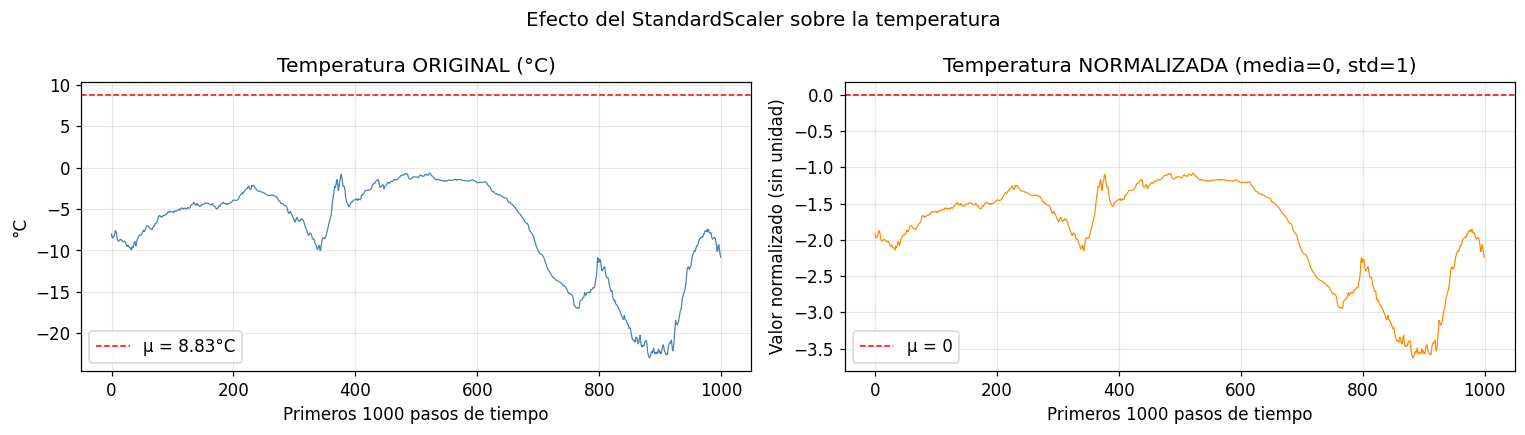

In [ ]:
temp_raw  = temperature[:num_train_samples]     # Sin normalizar (°C)
temp_norm = raw_data_norm[:num_train_samples, 1]  # Normalizada (índice 1)

# Mostramos solo los primeros 1000 pasos para claridad visual
n_show = 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(temp_raw[:n_show], color='steelblue', linewidth=0.8)
axes[0].set_title('Temperatura ORIGINAL (°C)')
axes[0].set_ylabel('°C')
axes[0].axhline(temp_mean, color='red', linestyle='--', linewidth=1,
                label=f'μ = {temp_mean:.2f}°C')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(temp_norm[:n_show], color='darkorange', linewidth=0.8)
axes[1].set_title('Temperatura NORMALIZADA (media=0, std=1)')
axes[1].set_ylabel('Valor normalizado (sin unidad)')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1, label='μ = 0')
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.set_xlabel(f'Primeros {n_show} pasos de tiempo')

plt.suptitle('Efecto del StandardScaler sobre la temperatura', fontsize=13)
plt.tight_layout()
plt.show()

---
## Concepto: Ventana Deslizante (Sliding Window)

Para entrenar una RNN necesitamos pares **(secuencia_entrada X, objetivo y)**.
Los creamos con una **ventana deslizante** sobre la serie temporal:

```
Serie: [t0, t1, t2, t3, t4, t5, t6, ... , tN]

Ventana 1:  X = [t0, t1, t2, ..., t119]   →   y = t[0 + delay]
Ventana 2:  X = [t1, t2, t3, ..., t120]   →   y = t[1 + delay]
Ventana 3:  X = [t2, t3, t4, ..., t121]   →   y = t[2 + delay]
...
```

### Parámetros clave:

| Parámetro | Valor | Significado |
|---|---|---|
| `sampling_rate` | 6 | Tomamos 1 muestra cada 6 pasos → 1 muestra/hora |
| `sequence_length` | 120 | Cada X tiene 120 pasos → 120 horas = 5 días de historia |
| `delay` | `6 × (120 + 24 - 1)` | Predecimos 24h adelante del último paso de la secuencia |

```
Diagrama de una sola muestra:

  t0    t6    t12  ...  t714          t858
  │     │     │         │              │
  X[0]  X[1]  X[2] ...  X[119]        y  ← temperatura 24h después
  │←────────── 5 días de historia ────►│◄──── 24h gap ────►│
```


---
## Celda 9 — Hiperparámetros de la ventana deslizante


In [ ]:
# ─── Frecuencia de muestreo ───────────────────────────────────────────────────
# Los datos originales tienen 1 muestra cada 10 min.
# Con sampling_rate=6 tomamos 1 muestra cada 60 min → reducimos ×6 el tamaño.
sampling_rate = 6

# ─── Longitud de la secuencia de entrada ─────────────────────────────────────
# La RNN verá 120 pasos (cada uno = 1 hora) → 5 días de historia.
sequence_length = 120

# ─── Delay (horizonte de predicción) ─────────────────────────────────────────
# Queremos predecir la temperatura 24 horas después del ÚLTIMO paso de la secuencia.
#
# El último paso de X está en:  start + (sequence_length - 1) * sampling_rate
# El objetivo y está en:         start + delay
#
# Por lo tanto:
#   delay = sampling_rate * (sequence_length + 24 - 1)
#         = 6 * (120 + 23)
#         = 6 * 143 = 858 pasos = 143 horas ≈ 6 días
#
# ¿Por qué +23 y no +24?  Porque sequence_length ya cubre el último paso,
# así que el gap real desde el START hasta Y es sequence_length + 24 - 1.
delay = sampling_rate * (sequence_length + 24 - 1)

print('=' * 55)
print('PARÁMETROS DE LA VENTANA DESLIZANTE')
print('=' * 55)
print(f'  sampling_rate     : {sampling_rate}  (1 muestra cada {sampling_rate*10} min = 1h)')
print(f'  sequence_length   : {sequence_length}  pasos = {sequence_length} horas = {sequence_length//24} días de historia')
print(f'  delay             : {delay}  pasos = {delay*10//60} horas')
print()
print(f'  Historia de entrada : {sequence_length} horas ({sequence_length//24} días)')
print(f'  Predicción a        : 24 horas en el futuro')
print()
print(f' Muestras inválidas al final : {delay} (por el delay)')
print(f'     → Muestras válidas totales  : {N - delay:,}')

PARÁMETROS DE LA VENTANA DESLIZANTE
  sampling_rate     : 6  (1 muestra cada 60 min = 1h)
  sequence_length   : 120  pasos = 120 horas = 5 días de historia
  delay             : 858  pasos = 143 horas

  Historia de entrada : 120 horas (5 días)
  Predicción a        : 24 horas en el futuro

 Muestras inválidas al final : 858 (por el delay)
     → Muestras válidas totales  : 419,593


---
## Celda 10 — Visualizar la ventana deslizante

Mostramos concretamente cómo se construye un par (X, y) a partir de la serie temporal.


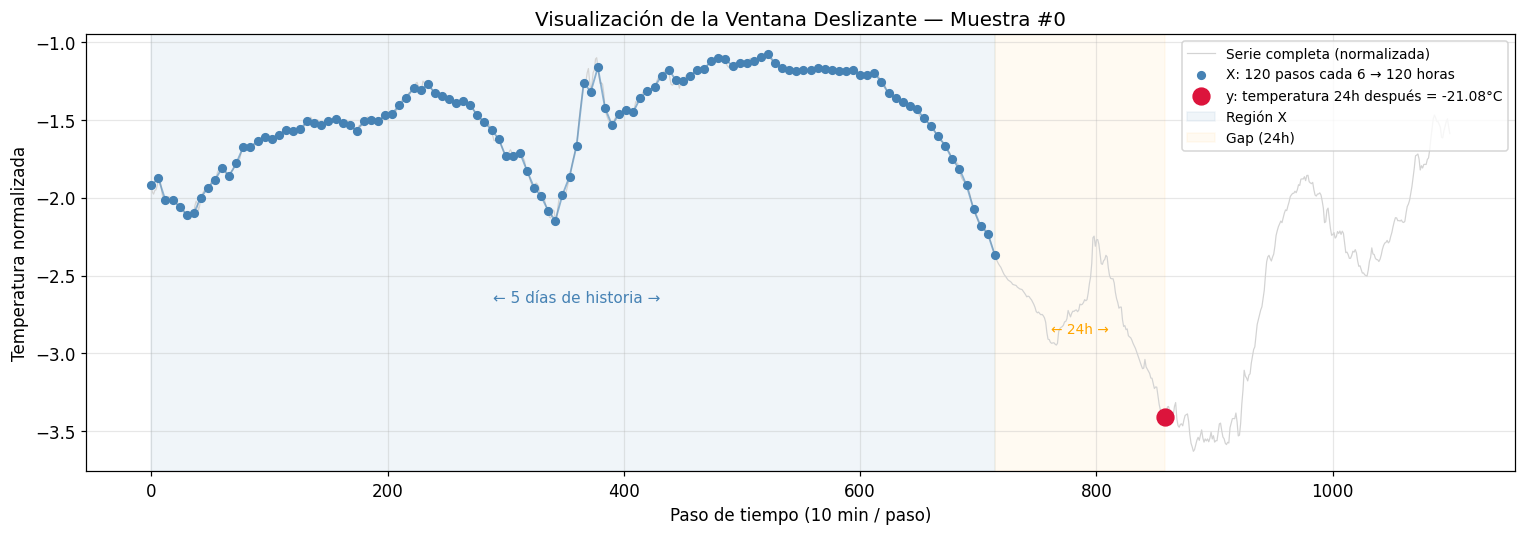

Forma de X[0]: (120,)  ← (sequence_length,)
Valor de y[0]: -21.0800 °C  ← temperatura real 24h después


In [ ]:
# Usamos temperatura normalizada para el ejemplo
temperature_normalized = (temperature - temp_mean) / temp_std

# Simulamos la ventana 0 (primer sample posible)
start = 0
steps = np.arange(start, start + sequence_length * sampling_rate, sampling_rate)
X_example = temperature_normalized[steps]  # shape: (120,)
y_example  = temperature[start + delay]     # escalar — temperatura real en °C

# ─── Gráfica ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

# Serie completa de fondo (primeros ~1000 pasos originales)
x_full = np.arange(0, 1100)
ax.plot(x_full, temperature_normalized[:1100],
        color='lightgray', linewidth=0.8, label='Serie completa (normalizada)')

# Puntos de la secuencia X (submuestreados)
ax.scatter(steps, X_example, color='steelblue', s=25, zorder=5,
           label=f'X: {sequence_length} pasos cada {sampling_rate} → {sequence_length} horas')
ax.plot(steps, X_example, color='steelblue', linewidth=1.2, alpha=0.6)

# Punto objetivo y
ax.scatter([start + delay], [temperature_normalized[start + delay]],
           color='crimson', s=120, zorder=6,
           label=f'y: temperatura 24h después = {y_example:.2f}°C')

# Líneas de región
ax.axvspan(steps[0],  steps[-1], alpha=0.08, color='steelblue', label='Región X')
ax.axvspan(steps[-1], start + delay, alpha=0.05, color='orange', label='Gap (24h)')

# Anotaciones
ax.annotate('← 5 días de historia →',
            xy=(steps[60], X_example.min() - 0.3),
            fontsize=10, color='steelblue', ha='center')
ax.annotate('← 24h →',
            xy=((steps[-1] + start + delay) / 2, X_example.min() - 0.5),
            fontsize=9, color='orange', ha='center')

ax.set_title('Visualización de la Ventana Deslizante — Muestra #0', fontsize=13)
ax.set_xlabel('Paso de tiempo (10 min / paso)')
ax.set_ylabel('Temperatura normalizada')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Forma de X[0]: {X_example.shape}  ← (sequence_length,)')
print(f'Valor de y[0]: {y_example:.4f} °C  ← temperatura real 24h después')

---
## Celda 11 — Baseline: Predicción Naive

Antes de entrenar cualquier modelo, calculamos un **baseline naive**:
predecir simplemente que la temperatura en 24h será **igual a la de ahora**.

> Si nuestro modelo no supera este baseline, **no está aprendiendo nada útil**.
> Es el piso mínimo de rendimiento que debemos superar.


In [ ]:
# Baseline: predecir que y[t] = temperatura[t]  (sin cambio en 24h)
#
# MAE naive = mean(|T[t + delay] - T[t]|)
#
# Calculamos sobre todo el dataset para tener una referencia global.

y_true  = temperature[delay:]   # temperatura real en t + delay
y_naive = temperature[:-delay]  # "predicción" = temperatura actual

mae_naive = np.mean(np.abs(y_true - y_naive))

print('=' * 55)
print('BASELINE NAIVE ("la temperatura no cambia")')
print('=' * 55)
print(f'  MAE baseline global : {mae_naive:.4f} °C')
print()
print('  → Nuestro modelo RNN debe obtener un MAE < {:.2f}°C'.format(mae_naive))
print('    para demostrar que realmente ha aprendido algo.')

# Guardamos para comparar luego
mae_naive_global = mae_naive

BASELINE NAIVE ("la temperatura no cambia")
  MAE baseline global : 4.5057 °C

  → Nuestro modelo RNN debe obtener un MAE < 4.51°C
    para demostrar que realmente ha aprendido algo.


---
## Celda 12 — Guardar datos procesados

Guardamos todo lo necesario para la **Parte 4 (entrenamiento RNN)**:
- `raw_data.npy` — datos normalizados (todas las features)
- `temperature.npy` — temperatura original en °C (para targets y métricas)
- `train/val/test_idx.npy` — índices de cada split
- `scaler.pkl` — para desnormalizar predicciones después
- `baseline_mae.npy` — MAE del modelo naive (referencia)


In [ ]:
save_dir = 'data/processed'
os.makedirs(save_dir, exist_ok=True)

# Arrays numéricos
np.save(os.path.join(save_dir, 'raw_data.npy'),    raw_data_norm)  # normalizado
np.save(os.path.join(save_dir, 'temperature.npy'), temperature)    # original en °C

# Índices de splits
np.save(os.path.join(save_dir, 'train_idx.npy'), train_idx)
np.save(os.path.join(save_dir, 'val_idx.npy'),   val_idx)
np.save(os.path.join(save_dir, 'test_idx.npy'),  test_idx)

# Baseline MAE
np.save(os.path.join(save_dir, 'baseline_mae.npy'), np.array([mae_naive_global]))

# Scaler (para desnormalizar predicciones en la Parte 4)
joblib.dump(scaler, os.path.join(save_dir, 'scaler.pkl'))

print('=' * 55)
print(f'💾 Archivos guardados en: {save_dir}/')
print('=' * 55)
for f in sorted(os.listdir(save_dir)):
    size_kb = os.path.getsize(os.path.join(save_dir, f)) / 1024
    print(f'  {f:<30s}  {size_kb:8.1f} KB')

---
## Celda 13 — Resumen final

Verificación de que todo está listo para la Parte 4.


In [ ]:
print('╔══════════════════════════════════════════════════════╗')
print('║         RESUMEN — RNN Parte 1: Datos listos          ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Dataset   : Jena Climate 2009–2016                  ║')
print(f'║  Muestras  : {N:,} pasos de 10 min              ║')
print(f'║  Features  : {raw_data_norm.shape[1]} variables meteorológicas          ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Train  : {num_train_samples:>7,} muestras  ({num_train_samples/N*100:.0f}%)                ║')
print(f'║  Val    : {num_val_samples:>7,} muestras  ({num_val_samples/N*100:.0f}%)                ║')
print(f'║  Test   : {num_test_samples:>7,} muestras  ({num_test_samples/N*100:.0f}%)                ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Sampling rate     : {sampling_rate} (1 hora por paso)           ║')
print(f'║  Sequence length   : {sequence_length} pasos (5 días de historia)  ║')
print(f'║  Delay             : {delay} pasos (24h de horizonte)   ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Baseline MAE (naive): {mae_naive_global:.4f} °C                  ║')
print(f'║  → Meta: MAE < {mae_naive_global:.2f}°C con la RNN              ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  Archivos guardados en: data/processed/              ║')
print(f'║  Listo para RNN Parte 4 — Entrenamiento           ║')
print('╚══════════════════════════════════════════════════════╝')

╔══════════════════════════════════════════════════════╗
║         RESUMEN — RNN Parte 1: Datos listos          ║
╠══════════════════════════════════════════════════════╣
║  Dataset   : Jena Climate 2009–2016                  ║
║  Muestras  : 420,451 pasos de 10 min              ║
║  Features  : 14 variables meteorológicas          ║
╠══════════════════════════════════════════════════════╣
║  Train  : 210,225 muestras  (50%)                ║
║  Val    : 105,112 muestras  (25%)                ║
║  Test   : 105,114 muestras  (25%)                ║
╠══════════════════════════════════════════════════════╣
║  Sampling rate     : 6 (1 hora por paso)           ║
║  Sequence length   : 120 pasos (5 días de historia)  ║
║  Delay             : 858 pasos (24h de horizonte)   ║
╠══════════════════════════════════════════════════════╣
║  Baseline MAE (naive): 4.5057 °C                  ║
║  → Meta: MAE < 4.51°C con la RNN              ║
╠══════════════════════════════════════════════════════╣
║  Ar